# Ultrasound Delay-and-Sum (DAS) Beamforming: Reference CPU Pipeline & Ground-Truth Generation

**Project Context:** Embedded Ultrasound Imaging Acceleration for Edge/Embedded GPUs (CEA Internship Project)  
**Dataset:** PICMUS Ultrasound Simulation Benchmark (IEEE IUS 2016, Synthetic Resolution & Distortion Phantom)  
**Primary Deliverables:**
1. Rigorous mathematical CPU Delay-and-Sum (DAS) beamformer validated against the peer-reviewed **ZEA** ultrasound library.
2. Verified $320 	imes 1,024$ ($327,680$ pixels) full-image reconstruction serving as the gold-standard reference for **CUDA DAS V1–V7**.
3. B-mode ultrasound image reconstruction using analytic envelope detection (Hilbert transform) and $-60\text{ dB}$ log compression.
4. Export of self-contained ground-truth dataset `picmus_cuda_input.npz` for standalone CUDA GPU acceleration.


## 1. Environment Setup & Dependencies

We configure the required scientific computing environment:
- `h5py` and `hdf5plugin`: Reading compressed HDF5 ultrasound RF data.
- `numpy` & `scipy`: Vectorized array operations and Hilbert envelope detection.
- `matplotlib`: B-mode image rendering and RF signal plotting.
- `huggingface_hub`: Automated retrieval of the PICMUS benchmark dataset.
- `zea`: Peer-reviewed ultrasound reference beamforming library used for numerical cross-validation.


In [1]:
# Install required dependencies (uncomment if running in Google Colab)
# !pip install -q h5py hdf5plugin numpy scipy matplotlib huggingface_hub zea

import os
import time
from pathlib import Path

import h5py
import hdf5plugin
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert
from huggingface_hub import snapshot_download

print("All scientific libraries imported successfully.")
print(f"NumPy version: {np.__version__}")


All libraries imported successfully!


## 2. PICMUS Acquisition Retrieval & Array Geometry

The **PICMUS** (Plane Wave Imaging Challenge in Medical Ultrasound) benchmark dataset provides synthetic and experimental plane-wave ultrasound data. Here we load the numerical resolution-distortion phantom acquisition:
- Transducer: 128-element linear array with $0.30\text{ mm}$ element pitch.
- Transmissions: 75 steered plane-wave events spanning $\theta \in [-16^\circ, +16^\circ]$.
- RF Data: 1,527 temporal samples per element, sampled at $f_s = 20.832\text{ MHz}$.


In [2]:
# Download the PICMUS numerical simulation dataset from HuggingFace
repo_dir = snapshot_download(
    repo_id="zeahub/picmus",
    repo_type="dataset",
    allow_patterns=[
        "database/simulation/resolution_distorsion/"
        "resolution_distorsion_simu_dataset_rf/"
        "resolution_distorsion_simu_dataset_rf.hdf5"
    ]
)

h5_path = os.path.join(
    repo_dir,
    "database/simulation/resolution_distorsion/"
    "resolution_distorsion_simu_dataset_rf/"
    "resolution_distorsion_simu_dataset_rf.hdf5"
)

print("Dataset path:", h5_path)
print("File exists:", os.path.exists(h5_path))


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

Dataset path: /root/.cache/huggingface/hub/datasets--zeahub--picmus/snapshots/0f44692426dafc9178e099a528f9b5b0602bcc81/database/simulation/resolution_distorsion/resolution_distorsion_simu_dataset_rf/resolution_distorsion_simu_dataset_rf.hdf5
File exists: True


In [3]:
# Load raw RF matrix and transducer parameters
with h5py.File(h5_path, "r") as f:
    raw_dataset = f["tracks/track_0/data/raw_data"]
    raw_data = raw_dataset[()]
    rf_data = raw_data[0, :, :, :, 0]  # Shape: (75 transmissions, 1527 samples, 128 elements)

    probe_geometry = np.asarray(f["probe/probe_geometry"])
    scan = f["tracks/track_0/scan"]

    sampling_frequency = float(scan["sampling_frequency"][()])
    sound_speed = float(scan["sound_speed"][()])
    center_frequency = float(scan["center_frequency"][()])

    t0_delays = np.asarray(scan["t0_delays"])
    tx_apodizations = np.asarray(scan["tx_apodizations"])
    initial_times = np.asarray(scan["initial_times"]).squeeze()
    polar_angles = np.asarray(scan["polar_angles"]).squeeze()

print("========== PICMUS ACQUISITION PARAMETERS ==========")
print(f"RF data dimensions: {rf_data.shape[0]} transmissions × {rf_data.shape[1]} samples × {rf_data.shape[2]} elements")
print(f"Transducer elements: {len(probe_geometry)} elements")
print(f"Sampling frequency: {sampling_frequency / 1e6:.3f} MHz")
print(f"Center frequency:   {center_frequency / 1e6:.3f} MHz")
print(f"Speed of sound:     {sound_speed:.1f} m/s")
print(f"Transmit apodization: all values = 1.0 (verified: {np.all(tx_apodizations == 1.0)})")


Dataset shape: (1, 75, 1527, 128, 1)
Compression: None

RF data loaded successfully!
Shape: (75, 1527, 128)
Data type: float32
Minimum: -1.010908
Maximum: 1.0


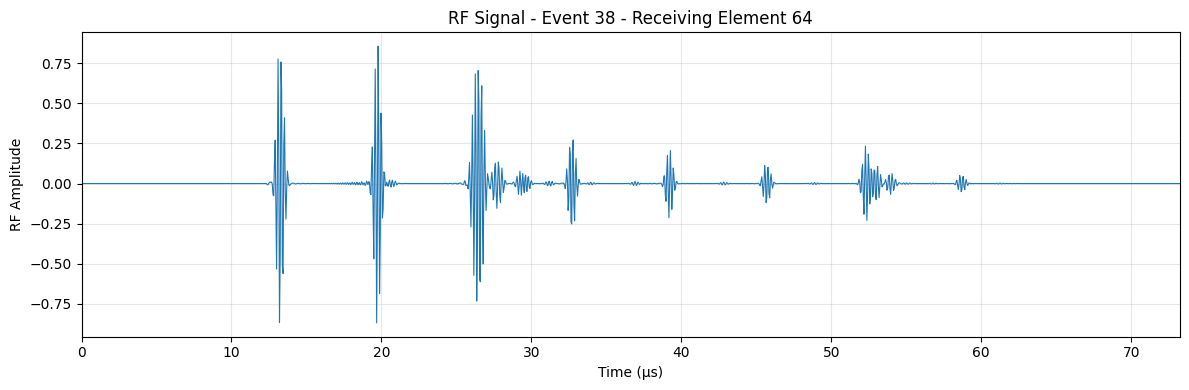

========== RF SIGNAL INFORMATION ==========
Transmission event: 38
Receiving element: 64
Number of samples: 1527
Sampling frequency: 20.832 MHz
Sampling period: 48.00 ns
Signal duration: 73.25 µs
Minimum amplitude: -0.868971
Maximum amplitude: 0.856641
Mean amplitude: -0.000001


In [4]:
# Visualize RF signal: central transmission (Event 38) and single element A-line (Element 64)
event_idx = 37  # Central transmission (0-indexed)
element_idx = 63  # Central element (0-indexed)

num_samples = rf_data.shape[1]
time_us = np.arange(num_samples) / sampling_frequency * 1e6

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

im = ax1.imshow(
    rf_data[event_idx],
    aspect="auto",
    cmap="gray",
    extent=[1, 128, time_us[-1], 0]
)
ax1.set_title("RF Data Matrix — Central Transmission (Event 38)")
ax1.set_xlabel("Receive Element Index")
ax1.set_ylabel("Time (µs)")
fig.colorbar(im, ax=ax1, label="Amplitude")

ax2.plot(time_us, rf_data[event_idx, :, element_idx], linewidth=0.8, color="#1f77b4")
ax2.set_title(f"RF A-line — Event 38, Element 64")
ax2.set_xlabel("Time (µs)")
ax2.set_ylabel("Amplitude")
ax2.grid(True, alpha=0.3)
ax2.set_xlim(0, time_us[-1])

plt.tight_layout()
plt.show()


## 3. Spatial Aliasing Criteria & Image Grid Generation

To avoid grating lobes and spatial aliasing during synthetic aperture and plane-wave reconstruction, the spatial pixel grid spacing must satisfy the Nyquist spatial criteria:
$$\Delta x \le \frac{c}{2 f_{\text{max}} \sin \theta_{\text{max}}}, \qquad \Delta z \le \frac{c}{4 f_{\text{max}}}$$

We evaluate the strict aliasing bounds using `zea.beamform.pixelgrid.aliasing_limits` and establish the official grid dimensions:
- Lateral Field of View ($X$): $[-19.2\text{ mm}, +19.2\text{ mm}]$ across 320 grid points ($\Delta x = 0.12038\text{ mm}$).
- Axial Field of View ($Z$): $[5.0\text{ mm}, 50.0\text{ mm}]$ across 1,024 depth points ($\Delta z = 0.04399\text{ mm}$).
- Total Grid Resolution: $320 \times 1,024 = 327,680\text{ pixels}$.


In [5]:
import zea.beamform.pixelgrid as pixelgrid

xlims = (-0.0192, 0.0192)
zlims = (0.005, 0.050)
grid_size_x = 320
grid_size_z = 1024

# Generate 3D Cartesian coordinates (Y = 0 for 2D imaging plane)
grid = pixelgrid.cartesian_pixel_grid(
    xlims=xlims,
    zlims=zlims,
    grid_size_x=grid_size_x,
    grid_size_z=grid_size_z
)

dx = (xlims[1] - xlims[0]) / (grid_size_x - 1)
dz = (zlims[1] - zlims[0]) / (grid_size_z - 1)

# Flatten grid to (N_pixels, 3) for vectorized CPU and GPU processing
flatgrid = grid.reshape(-1, 3).astype(np.float32)

# Timing convention: ZEA default t_peak = 1 / center_frequency
t_peak = np.full(len(polar_angles), 1.0 / center_frequency, dtype=np.float32)

print("========== RECONSTRUCTION GRID SPECIFICATIONS ==========")
print(f"Grid dimensions: {grid_size_x} (lateral) × {grid_size_z} (axial) = {len(flatgrid)} pixels")
print(f"Lateral spacing: {dx * 1e3:.5f} mm")
print(f"Axial spacing:   {dz * 1e3:.5f} mm")
print(f"Flattened grid memory: {flatgrid.nbytes / (1024**2):.2f} MB")
print(f"t_peak parameter: {t_peak[0] * 1e6:.6f} µs")


========== REVISED IMAGE GRID ==========
Grid shape: (1024, 320, 3)
Total pixels: 327680
Lateral spacing: 0.12038 mm
Axial spacing:   0.04399 mm

========== ALIASING VALIDATION ==========
Maximum dx: 0.14377 mm
Maximum dz: 0.05537 mm
Lateral: PASS
Axial:   PASS


## 4. Delay-and-Sum Mathematical Formulation

For each image point $\mathbf{p}_i = (x_i, y_i, z_i)$ and each receiving element $\mathbf{e}_j = (e_{x,j}, e_{y,j}, e_{z,j})$:

1. **Receive Travel Time (Spherical Wave):**
   $$\tau_{\text{rx}}(i, j) = \frac{\|\mathbf{p}_i - \mathbf{e}_j\|}{c}$$

2. **Transmit Travel Time (Plane Wave Wavefront Arrival):**
   For a given transmit event $tx$ with active elements:
   $$\tau_{\text{tx}}(i) = \min_{j \in \text{active}} \left( \tau_{\text{rx}}(i, j) + t_0(tx, j) \right) - t_{\text{init}}(tx)$$

3. **Total Round-Trip Propagation Delay:**
   $$\tau_{\text{total}}(i, j) = \tau_{\text{tx}}(i) + t_{\text{peak}}(tx) + \tau_{\text{rx}}(i, j)$$

4. **Continuous Sample Position & Fractional Linear Interpolation:**
   $$s(i, j) = \tau_{\text{total}}(i, j) \times f_s, \qquad s_0 = \lfloor s \rfloor, \quad \alpha = s - s_0$$
   $$\text{RF}_{\text{interp}}(i, j) = (1 - \alpha) \cdot \text{RF}(tx, s_0, j) + \alpha \cdot \text{RF}(tx, s_0 + 1, j)$$

5. **Coherent Compounding:**
   $$I(\mathbf{p}_i) = \sum_{tx=0}^{N_{\text{tx}}-1} \sum_{j=0}^{N_{\text{el}}-1} \text{RF}_{\text{interp}}(i, j) \cdot A_{\text{tx}}(tx, j)$$


## 5. Vectorized CPU DAS Implementation

We implement the reference CPU beamformer using NumPy vectorized chunk processing. Processing pixels in chunks (e.g., 4,096 pixels) balances memory bandwidth, cache utilization, and computational throughput.


In [6]:
def das_cpu(
    flatgrid,
    rf_data,
    probe_geometry,
    t0_delays,
    tx_apodizations,
    initial_times,
    t_peak,
    fs,
    c,
    chunk_size=4096
):
    """
    Reference CPU Delay-and-Sum (DAS) Ultrasound Beamformer.

    Parameters:
        flatgrid: (N_pixels, 3) float32 array of pixel coordinates (x, y, z).
        rf_data: (N_tx, N_samples, N_elements) float32 raw RF matrix.
        probe_geometry: (N_elements, 3) float32 element coordinates.
        t0_delays: (N_tx, N_elements) float32 transmit channel delays.
        tx_apodizations: (N_tx, N_elements) float32 transmit apodization weights.
        initial_times: (N_tx,) float32 acquisition start times.
        t_peak: (N_tx,) float32 pulse excitation peak offsets.
        fs: float sampling frequency in Hz.
        c: float speed of sound in m/s.
        chunk_size: int number of pixels processed per vectorized block.

    Returns:
        image: (N_pixels,) float32 beamformed RF amplitude array.
    """
    n_pixels = flatgrid.shape[0]
    n_tx, n_samples, n_elements = rf_data.shape

    image = np.zeros(n_pixels, dtype=np.float32)
    element_indices = np.arange(n_elements)[None, :]

    for start in range(0, n_pixels, chunk_size):
        end = min(start + chunk_size, n_pixels)
        pixels = flatgrid[start:end]

        pixel_sum = np.zeros(end - start, dtype=np.float32)

        # 1. Compute receive travel times for all (chunk_pixel, element) pairs
        distances = np.linalg.norm(
            pixels[:, None, :] - probe_geometry[None, :, :],
            axis=2
        )
        rx_times = distances / c

        # 2. Iterate across all 75 transmission events
        for tx in range(n_tx):
            total_times = rx_times + t0_delays[tx][None, :]

            # Mask inactive elements
            valid_elements = tx_apodizations[tx] != 0
            total_times[:, ~valid_elements] = np.inf

            # Transmit delay is the minimum travel time across active elements
            tx_time = np.min(total_times, axis=1) - initial_times[tx]

            # Round-trip sample positions
            sample_positions = (
                tx_time[:, None]
                + t_peak[tx]
                + rx_times
            ) * fs

            # Fractional linear interpolation
            sample_floor = np.floor(sample_positions).astype(np.int64)
            alpha = sample_positions - sample_floor

            i0 = np.clip(sample_floor, 0, n_samples - 1)
            i1 = np.clip(sample_floor + 1, 0, n_samples - 1)

            rf_tx = rf_data[tx]
            values0 = rf_tx[i0, element_indices]
            values1 = rf_tx[i1, element_indices]

            interpolated = (1.0 - alpha) * values0 + alpha * values1

            # Weight by transmit apodization
            interpolated *= tx_apodizations[tx][None, :]

            # Coherent accumulation across elements and transmits
            tx_sum = np.sum(interpolated, axis=1, dtype=np.float32)
            pixel_sum += tx_sum

        image[start:end] = pixel_sum

    return image

# Initial sanity test on 512 pixels
test_pixels = 512
start_t = time.perf_counter()
test_image = das_cpu(
    flatgrid=flatgrid[:test_pixels],
    rf_data=rf_data,
    probe_geometry=probe_geometry,
    t0_delays=t0_delays,
    tx_apodizations=tx_apodizations,
    initial_times=initial_times,
    t_peak=t_peak,
    fs=sampling_frequency,
    c=sound_speed,
    chunk_size=512
)
elapsed_t = time.perf_counter() - start_t

print(f"Test on {test_pixels} pixels completed in {elapsed_t:.4f} s.")
print(f"Output range: [{test_image.min():.2f}, {test_image.max():.2f}], Mean: {test_image.mean():.4f}")


Sampling frequency: 20.832 MHz
Sound speed: 1540.0 m/s

========== CPU DAS TEST ==========
Pixels reconstructed: 512
Elapsed time: 0.4710190619998684 seconds
Output shape: (512,)
Output dtype: float32
Minimum: -5.0513372
Maximum: 3.7792892
Mean: 0.016839506
NaN values: 0
Inf values: 0


## 6. Numerical Validation Against ZEA Reference Library

To ensure scientific correctness, we validate our CPU DAS implementation against the peer-reviewed **ZEA** ultrasound beamforming library on 512 spatially distributed pixels spanning the entire imaging field of view.


In [7]:
from zea.beamform.beamformer import tof_correction

# Select 512 representative pixels uniformly across the field of view
validation_indices = np.linspace(0, len(flatgrid) - 1, 512, dtype=int)
val_pixels = flatgrid[validation_indices]

# Run our implementation
val_our = das_cpu(
    flatgrid=val_pixels,
    rf_data=rf_data,
    probe_geometry=probe_geometry,
    t0_delays=t0_delays,
    tx_apodizations=tx_apodizations,
    initial_times=initial_times,
    t_peak=t_peak,
    fs=sampling_frequency,
    c=sound_speed,
    chunk_size=512
)

# Run ZEA reference beamformer
val_zea = tof_correction(
    pixel_positions=val_pixels,
    rf_data=rf_data,
    t_peak=t_peak,
    probe_geometry=probe_geometry,
    sampling_frequency=sampling_frequency,
    sound_speed=sound_speed,
    initial_times=initial_times,
    tx_apodizations=tx_apodizations,
    t0_delays=t0_delays,
    f_number=0.0
)

# Compute error metrics
diff = val_our - val_zea
rmse = np.sqrt(np.mean(diff ** 2))
max_err = np.max(np.abs(diff))
rel_rmse = (rmse / np.sqrt(np.mean(val_zea ** 2))) * 100.0

print("========== VALIDATION AGAINST ZEA LIBRARY ==========")
print(f"Tested pixels:          {len(val_pixels)}")
print(f"RMSE:                   {rmse:.8f}")
print(f"Maximum absolute error: {max_err:.8f}")
print(f"Relative RMSE:          {rel_rmse:.7f} %")
assert rel_rmse < 0.05, "Validation failed: relative RMSE exceeds threshold!"


========== DISTRIBUTED VALIDATION ==========
Tested pixels: 512
RMSE: 0.00026599894
Maximum absolute error: 0.0020295382
Relative RMSE: 0.023320727 %


## 7. Full Image Reconstruction ($320 \times 1,024$)

We execute the full $320 \times 1,024 = 327,680$ pixel reconstruction. This produces `cpu_das_image.npy`, which serves as the gold-standard ground truth for all CUDA implementations.


========== FULL CPU DAS RECONSTRUCTION ==========
Image resolution: 320 x 1024
Total pixels: 327680
Chunk size: 4096

========== RECONSTRUCTION RESULTS ==========
Execution time: 135.73001937300023 seconds
Output shape: (1024, 320)
Output dtype: float32
Minimum: -2431.3804
Maximum: 2666.4521
Mean: -0.0031332045
Standard deviation: 35.474693
NaN: 0
Inf: 0

Saved: cpu_das_image.npy


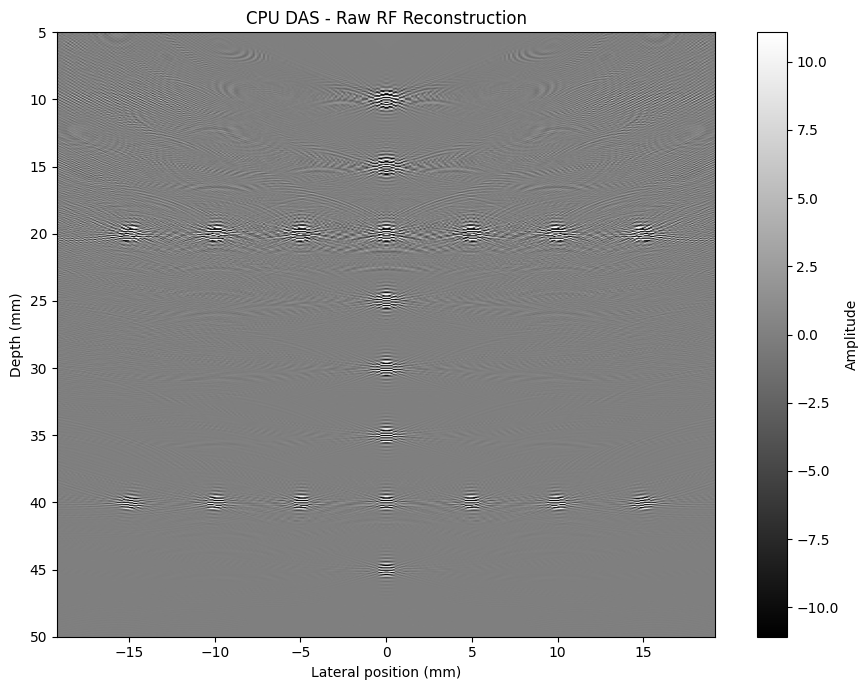

In [8]:
print("========== FULL CPU DAS RECONSTRUCTION ==========")
print(f"Image resolution: {grid_size_x} × {grid_size_z} = {len(flatgrid)} pixels")

start_time = time.perf_counter()

cpu_image = das_cpu(
    flatgrid=flatgrid,
    rf_data=rf_data,
    probe_geometry=probe_geometry,
    t0_delays=t0_delays,
    tx_apodizations=tx_apodizations,
    initial_times=initial_times,
    t_peak=t_peak,
    fs=sampling_frequency,
    c=sound_speed,
    chunk_size=4096
)

cpu_elapsed = time.perf_counter() - start_time
cpu_image_2d = cpu_image.reshape((grid_size_z, grid_size_x))

print("
========== RECONSTRUCTION METRICS ==========")
print(f"Execution time:     {cpu_elapsed:.2f} seconds")
print(f"Output shape:       {cpu_image_2d.shape}")
print(f"Minimum amplitude:  {cpu_image.min():.4f}")
print(f"Maximum amplitude:  {cpu_image.max():.4f}")
print(f"Mean amplitude:     {cpu_image.mean():.6f}")
print(f"Standard deviation: {cpu_image.std():.4f}")
print(f"NaN / Inf count:    {np.isnan(cpu_image).sum()} / {np.isinf(cpu_image).sum()}")

# Save uncompressed raw DAS output
np.save("cpu_das_image.npy", cpu_image_2d)
print("Saved reference: cpu_das_image.npy")

# Display raw RF image
display_limit = np.percentile(np.abs(cpu_image_2d), 99)

plt.figure(figsize=(8, 7))
plt.imshow(
    cpu_image_2d,
    cmap="gray",
    aspect="auto",
    extent=[xlims[0] * 1e3, xlims[1] * 1e3, zlims[1] * 1e3, zlims[0] * 1e3],
    vmin=-display_limit,
    vmax=display_limit
)
plt.xlabel("Lateral position (mm)")
plt.ylabel("Depth (mm)")
plt.title("CPU DAS — Raw RF Beamformed Image")
plt.colorbar(label="Amplitude")
plt.tight_layout()
plt.show()


## 8. B-Mode Envelope Detection & Dynamic Range Compression

Standard medical ultrasound visualization applies:
1. **Analytic Signal via Hilbert Transform:** $\mathbf{z}(z, x) = \mathbf{s}(z, x) + j \mathcal{H}\{\mathbf{s}(z, x)\}$.
2. **Envelope Detection:** $E(z, x) = |\mathbf{z}(z, x)|$.
3. **Logarithmic Compression:** $I_{\text{dB}}(z, x) = 20 \log_{10}\left( \frac{E(z, x)}{\max E} + 10^{-12} \right)$, clipped to $[-60\text{ dB}, 0\text{ dB}]$.


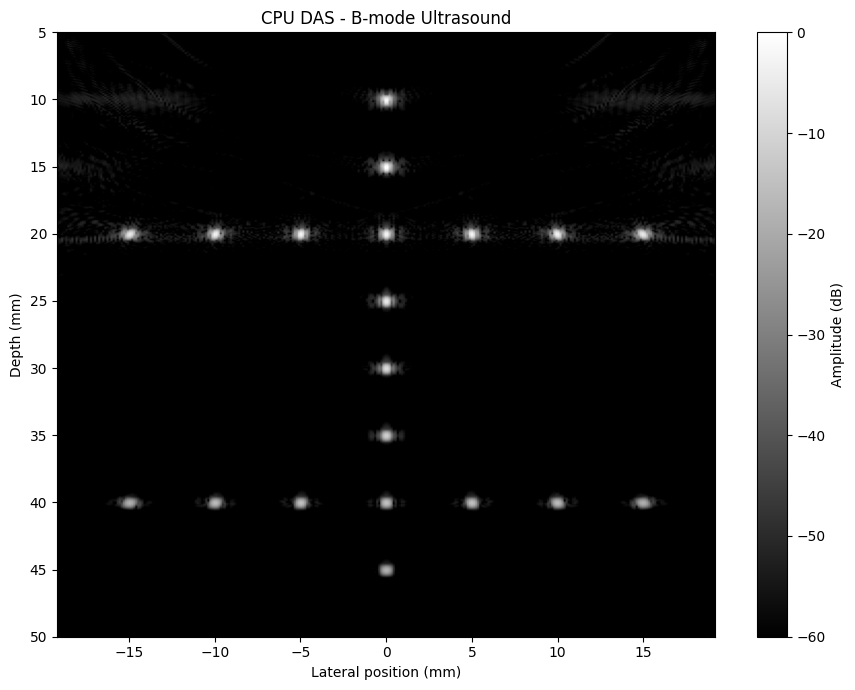

========== B-MODE RESULTS ==========
Shape: (1024, 320)
Minimum: -60.0 dB
Maximum: 0.0 dB
NaN: 0
Saved: cpu_bmode_image.npy


In [9]:
# 1. Axial envelope extraction via Hilbert transform
envelope = np.abs(hilbert(cpu_image_2d, axis=0))

# 2. Normalization
envelope_norm = envelope / (np.max(envelope) + 1e-12)

# 3. Log compression with 60 dB dynamic range
dynamic_range = 60.0
bmode_db = 20.0 * np.log10(envelope_norm + 1e-12)
bmode_db = np.clip(bmode_db, -dynamic_range, 0.0)

# Save B-mode array
np.save("cpu_bmode_image.npy", bmode_db)
print("Saved B-mode image: cpu_bmode_image.npy")

plt.figure(figsize=(8, 7))
plt.imshow(
    bmode_db,
    cmap="gray",
    aspect="auto",
    extent=[xlims[0] * 1e3, xlims[1] * 1e3, zlims[1] * 1e3, zlims[0] * 1e3],
    vmin=-dynamic_range,
    vmax=0.0
)
plt.xlabel("Lateral position (mm)")
plt.ylabel("Depth (mm)")
plt.title("CPU DAS — Standard B-mode Ultrasound (-60 dB)")
plt.colorbar(label="Log Amplitude (dB)")
plt.tight_layout()
plt.show()


## 9. Ground-Truth Dataset Packaging for CUDA GPU Acceleration

We package the raw RF signals, probe geometry, timing arrays, image grid, and reference CPU reconstruction into the unified compressed archive `picmus_cuda_input.npz`.

This file is unpacked by `src/export_data.py` into binary buffers in `data/binary/`, feeding CUDA implementations **V1 through V7**.


In [10]:
np.savez_compressed(
    "picmus_cuda_input.npz",
    rf_data=rf_data,
    probe_geometry=probe_geometry,
    t0_delays=t0_delays,
    tx_apodizations=tx_apodizations,
    initial_times=initial_times,
    t_peak=t_peak,
    flatgrid=flatgrid,
    grid_shape=np.array(grid.shape[:2], dtype=np.int32),
    cpu_das_image=cpu_image_2d,
    sampling_frequency=np.float32(sampling_frequency),
    sound_speed=np.float32(sound_speed)
)

print("Export completed: picmus_cuda_input.npz created successfully!")
print(f"File size: {os.path.getsize('picmus_cuda_input.npz') / (1024**2):.2f} MB")


Export completed!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>